1.1 How often does pole position turn into a win, by driver and by decade?



In [13]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("/home/aris/projects/F1-Analysis/data/processed/results_joined.csv", low_memory=False)

In [14]:
#Keep only the pole position drivers and then length of the amount of those drivers

poles = df[df["pole"]]
len(poles)

1179

In [15]:
# Share of pole sitters who went on to win, per decade
by_decade = poles.groupby("decade")["won"].mean() * 100
by_decade.round(1)

#Output takeaway is that in 1950 decade, 37.6% of pole starts ended in a win

decade
1950    37.6
1960    36.3
1970    36.8
1980    28.2
1990    42.6
2000    50.0
2010    50.5
2020    56.7
Name: won, dtype: float64

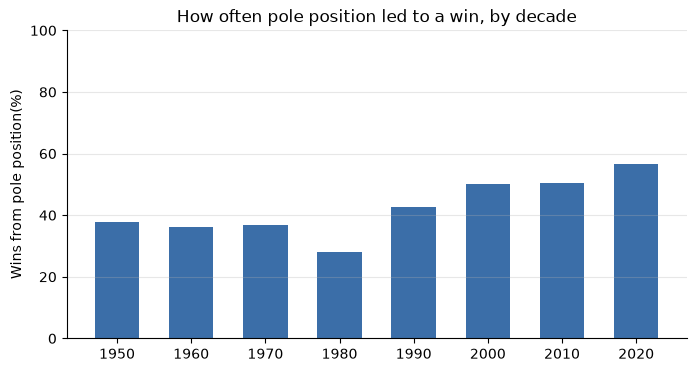

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_decade.index.astype(str), by_decade.values, color="#3b6ea8", width=0.6)
ax.set_title("How often pole position led to a win, by decade")
ax.set_ylabel("Wins from pole position(%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

From the 1950s to the 1970s, about 36–38% of pole starts ended in a win.
The 1980s stand out at 28.2%, much lower than the decades around them.
After the 1980s, the win rate from pole rises every decade and peaks in the 2020s at 56.7%.

In [17]:
# For each driver: how many poles, how many wins from pole, and the rate
by_driver = poles.groupby("driver").agg(poles=("won", "size"), wins=("won", "sum"))
by_driver["win_rate"] = (by_driver["wins"] / by_driver["poles"] * 100).round(1)

# Only drivers with at least 15 poles, best rate first
by_driver[by_driver["poles"] >= 15].sort_values("win_rate", ascending=False)

,poles,wins,win_rate
driver,,,
Max Verstappen,50,39,78.0
Fernando Alonso,22,14,63.6
Michael Schumacher,68,40,58.8
Lewis Hamilton,105,61,58.1
Alain Prost,33,18,54.5
Sebastian Vettel,57,31,54.4
Nigel Mansell,32,17,53.1
Lando Norris,19,10,52.6
Nico Rosberg,30,15,50.0


Among drivers with at least 15 poles, the five best at turning pole into a win are Max Verstappen, Fernando Alonso, Michael Schumacher, Lewis Hamilton and Alain Prost. Verstappen leads at 78.0%, 14.4 percentage points ahead of Alonso in second. Lewis Hamilton has the most pole starts of any driver, with 105.

1.2 How have retirements (crashes, mechanical failures) changed since the 1950s?

In [18]:
# Statuses that are not retirements.
not_retirements = ["Withdrew", "Did not start", "Disqualified", "Excluded"]
starters = df[~df["status"].isin(not_retirements)]
len(df), len(starters)



(26291, 25868)

In [19]:
# Share of starters who did NOT finish, per decade
finish_rate = starters.groupby("decade")["finished"].mean() * 100
retire_rate = 100 - finish_rate
retire_rate.round(1)

decade
1950    48.1
1960    44.6
1970    45.2
1980    51.8
1990    46.3
2000    29.5
2010    17.5
2020    12.4
Name: finished, dtype: float64

In [20]:
# Statuses that count as a crash
crash = ["Accident", "Collision", "Spun off", "Collision damage", "Fatal accident", "Damage", "Debris"]

# Statuses that are neither a crash nor clearly the car breaking
other = ["Retired", "Not classified", "Lapped", "Not restarted", "Stalled",
         "Physical", "Injury", "Injured", "Eye injury", "Illness", "Driver unwell",
         "Safety", "Safety concerns", "Safety belt", "Underweight",
         "Out of fuel", "Fuel rig", "Refuelling", "Puncture", "Tyre"]

# Give back "Crash", "Other" or "Mechanical" for one status
def retirement_type(status):
    if status in crash:
        return "Crash"
    elif status in other or status.startswith("+"):
        return "Other"
    else:
        return "Mechanical"

# Quick test on three examples
retirement_type("Engine"), retirement_type("Collision"), retirement_type("+3 Laps")

('Mechanical', 'Crash', 'Other')

In [22]:
#Only the starters who did NOT finish
retired = starters[~starters["finished"]]

#Run retirement_type on every row's status and store the answer in a new column
retired["reason"] = retired["status"].apply(retirement_type)

retired["reason"].value_counts()

reason
Mechanical    6069
Crash         2563
Other          668
Name: count, dtype: int64

In [23]:
#Only use years where the retirement reason was recorded
known_retired = retired[retired["year"] <= 2022]
known_starters = starters[starters["year"] <= 2022]

#Count retirements: one row per decade, one column per reason
counts = pd.crosstab(known_retired["decade"], known_retired["reason"])

#How many starters in each decade
starts = known_starters.groupby("decade").size()

#Turn counts into "% of starters"
rates = counts.div(starts, axis=0) * 100
rates.round(1)

reason,Crash,Mechanical,Other
decade,,,
1950,8.3,37.5,2.2
1960,6.0,36.1,2.5
1970,11.6,30.4,3.2
1980,12.7,36.6,2.6
1990,16.6,28.6,1.2
2000,10.8,17.3,1.3
2010,6.6,9.3,1.5
2020,6.7,6.5,0.6


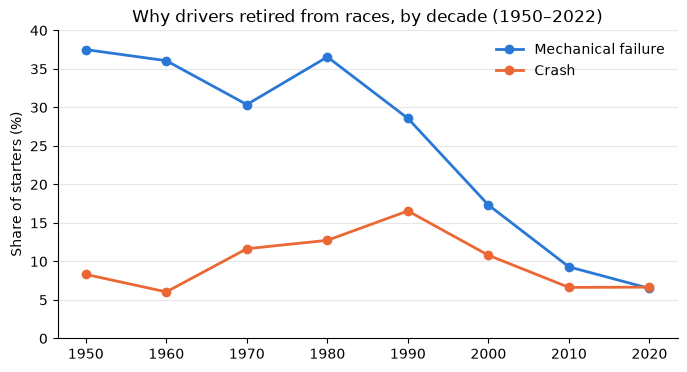

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rates.index, rates["Mechanical"], marker="o", linewidth=2, color="#2a78d6", label="Mechanical failure")
ax.plot(rates.index, rates["Crash"], marker="o", linewidth=2, color="#eb6834", label="Crash")
ax.set_title("Why drivers retired from races, by decade (1950–2022)")
ax.set_ylabel("Share of starters (%)")
ax.set_xticks(rates.index)
ax.set_ylim(0, 40)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()